# Домашнее задание 3. Градиентный спуск, Ньютон, BFGS: реализация и сравнение

**Выдано:** 7 октября 2026. **Срок сдачи:** 21 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Заполните этот ноутбук (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и сдайте через pull request: файл `submissions/hw03/<фамилия>.ipynb`, инструкция — [`CONTRIBUTING.md`](../../CONTRIBUTING.md). Задачи можно обсуждать, но текст и код пишутся самостоятельно.

**Материал:** лекция 4 ([конспект](../../lectures/lecture04/lecture04.md)) и лекция 5 ([конспект](../../lectures/lecture05/lecture05.md), [демо](../../lectures/lecture05/demo05.ipynb), [семинар](../../lectures/lecture05/seminar05.ipynb)). Ничего сверх лекций не требуется. Ориентировочное время — 3–4 часа.

**Устройство задания.** Обвязка — функции Розенброка, цепь, данные синуса, рисовальщики — дана готовой в ячейке ниже; вы пишете только то, что составляет метод: направление, выбор длины шага, обновление матрицы, шаг Гаусса–Ньютона. Под каждым заданием стоит проверка (`assert`), которая ловит смысл: если она прошла, можно идти дальше. Все методы работают с одними и теми же параметрами, чтобы числа совпали с конспектом: backtracking по Армихо с $c=10^{-4}$ от $\alpha=1$ делением пополам, останов по $\lVert\nabla f\rVert\le10^{-6}$ (у Ньютона — $10^{-10}$).

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`; в Colab ничего ставить не нужно.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, least_squares

rng = np.random.default_rng(2026)   # не меняйте seed: данные должны совпадать у всех

BLUE, ORANGE, AQUA, RED, VIOLET, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#4a3aa7", "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (даны готовыми)
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def make_chain(N, D=70.0, g=9.81):
    """Цепь без пола (лекция 1, §7.3; лекция 4): E(v) = 1/2 v^T H v + b^T v + const.
    Возвращает (energy, grad_E, H, b, v0): функция, градиент, гессиан, линейный член, старт (прямая между концами)."""
    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0; b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0; b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def energy(v):
        y, z = np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    return energy, (lambda v: H @ v + b), H, b, v0


# данные задачи 2(б) ДЗ 2: y = 2 sin(3t + 0.7) + шум, 60 точек, те же 20 стартов
data_rng = np.random.default_rng(2026)
t_data = np.sort(data_rng.uniform(0, 2 * np.pi, 60))
y_data = 2.0 * np.sin(3.0 * t_data + 0.7) + 0.2 * data_rng.standard_normal(60)
starts = data_rng.uniform(-5, 5, (20, 3))
X0_SINE = np.array([1.0, 3.0, 0.0])


def sine_resid(x):
    """Невязки модели x1 sin(x2 t + x3) на данных."""
    return x[0] * np.sin(x[1] * t_data + x[2]) - y_data


def sine_jac(x):
    """Якобиан невязок (60 x 3): столбцы — производные по амплитуде, частоте, фазе."""
    s, c = np.sin(x[1] * t_data + x[2]), np.cos(x[1] * t_data + x[2])
    return np.c_[s, x[0] * t_data * c, x[0] * c]


def sine_f(x):
    r = sine_resid(x); return 0.5 * (r @ r)


def sine_grad(x):
    return sine_jac(x).T @ sine_resid(x)


# ---------------------------------------------------------------- рисовальщики (принимают ax=None, возвращают ax)
def plot_rosen_path(paths, labels=None, ax=None, xlim=(-2.2, 2.2), ylim=(-3.5, 3.2), every=50):
    """Линии уровня Розенброка и пути методов; длинные пути прореживаются (каждая every-я точка после 30-й)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5))
    X, Y = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    ax.contour(X, Y, (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2, levels=np.logspace(-1, 3.3, 14), colors=[GRAY], linewidths=0.7)
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, p in enumerate(paths):
        pp = p if len(p) <= 60 else np.r_[p[:30], p[30::every]]
        ax.plot(pp[:, 0], pp[:, 1], "-o", ms=3 if len(p) > 60 else 4.5, lw=1.3, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.plot(1, 1, "*", ms=13, color=RED, mec="white", zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$"); ax.grid(False)
    if labels is not None:
        ax.legend(loc="upper left", fontsize=8)
    return ax


def plot_grad_norms(gnorms, labels=None, ax=None):
    """log10 нормы градиента по итерациям для нескольких методов (ось итераций логарифмическая)."""
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 4.2))
    colors = [BLUE, ORANGE, AQUA, VIOLET, RED]
    for i, gn in enumerate(gnorms):
        ax.plot(np.arange(1, len(gn) + 1), np.log10(np.asarray(gn) + 1e-17), "-o" if len(gn) < 60 else "-", ms=3.5, lw=1.4, color=colors[i % 5], label=None if labels is None else labels[i])
    ax.set_xscale("log"); ax.set(xlabel="итерация $k$ (лог. шкала)", ylabel="$\\log_{10}\\Vert\\nabla f(x_k)\\Vert$")
    if labels is not None:
        ax.legend(fontsize=8)
    return ax


print("данные синуса:", t_data.shape, " стартов ДЗ 2:", len(starts), " f в старте (1, 3, 0):", round(sine_f(X0_SINE), 3))

данные синуса: (60,)  стартов ДЗ 2: 20  f в старте (1, 3, 0): 33.867


## Задача 1. Теория (4 балла)

По 1 баллу за пункт. Нужны выкладки, а не только ответ; численная проверка приветствуется, но текстом объясните, почему так.

**(а) Один шаг Ньютона.** $f(x)=x_1^2+2x_2^2+x_1x_2-4x_1-7x_2$. Из точки $x_0=(0,0)$ сделайте один шаг Ньютона руками: выпишите $\nabla f(x_0)$, $\nabla^2f$, решите систему $Hp=-g$ и проверьте, что в новой точке $\nabla f=0$. Почему здесь хватило одной итерации и какое свойство функции за это отвечает?

**(б) Цифры удваиваются.** Метод Ньютона для $F(x)=x^2-a$ даёт $x_{k+1}=\tfrac12(x_k+a/x_k)$. Покажите, что ошибка $e_k=x_k-\sqrt a$ удовлетворяет $e_{k+1}=\dfrac{e_k^2}{2x_k}$. Для $a=3$, $x_0=2$ выпишите $x_1,x_2,x_3$ и ошибки; сколько верных цифр прибавляет каждый шаг?

**(в) Секущее уравнение для $B$.** Обновление BFGS для самого гессиана (не обратного): $B_{k+1}=B_k-\dfrac{B_ks_ks_k^\top B_k}{s_k^\top B_ks_k}+\dfrac{y_ky_k^\top}{y_k^\top s_k}$. Проверьте подстановкой, что $B_{k+1}s_k=y_k$. Почему для этого нужно $y_k^\top s_k\ne0$, и что это условие означает для функции?

**(г) Что отбрасывает Гаусс–Ньютон.** $f(x)=\tfrac12\lVert r(x)\rVert^2$, $r(x)=\big(x_1-2,\ x_2-1,\ x_1x_2-1\big)$. Выпишите $J$, $J^\top J$ и полный гессиан $\nabla^2f=J^\top J+\sum_ir_i\nabla^2r_i$. Где отброшенный член равен нулю? Есть ли у этой задачи точка, где все невязки нулевые, и что это значит для сходимости Гаусса–Ньютона рядом с ней?

**(а)**

**Ответ.** Градиент и гессиан равны
$$\nabla f(x)=\begin{pmatrix}2x_1+x_2-4\\x_1+4x_2-7\end{pmatrix},\qquad
H=\nabla^2f=\begin{pmatrix}2&1\\1&4\end{pmatrix},\qquad
\nabla f(0,0)=\begin{pmatrix}-4\\-7\end{pmatrix}.$$
Из $Hp=-g$ получаем $2p_1+p_2=4$, $p_1+4p_2=7$, то есть $p=(9/7,10/7)$. После полного шага $x_1=x_0+p$:
$$\nabla f(9/7,10/7)=\begin{pmatrix}18/7+10/7-4\\9/7+40/7-7\end{pmatrix}=0.$$
Гессиан квадратичной функции постоянен, поэтому её градиент линеен: один шаг Ньютона решает уравнение $\nabla f=0$ точно. Матрица $H$ положительно определена ($2>0$, $\det H=7>0$), следовательно, полученная точка — единственный минимум.

In [2]:
g0 = np.array([-4.0, -7.0])
H0 = np.array([[2.0, 1.0], [1.0, 4.0]])
p0 = np.linalg.solve(H0, -g0)
print("Шаг:", p0, "градиент после шага:", H0 @ p0 + g0)
assert np.allclose(p0, [9 / 7, 10 / 7])

Шаг: [1.28571429 1.42857143] градиент после шага: [0. 0.]


**(б)**

**Ответ.** Пусть $r=\sqrt a$, $x_k=r+e_k$. Тогда
$$e_{k+1}=\frac12\left(x_k+\frac{r^2}{x_k}\right)-r
=\frac{(x_k-r)^2}{2x_k}=\frac{e_k^2}{2x_k}.$$
Для $a=3$, $x_0=2$:
$$x_1=\frac74=1.75,\quad x_2=\frac{97}{56}\approx1.7321428571,\quad
x_3=\frac{18817}{10864}\approx1.7320508100.$$
Соответствующие ошибки $e_k=x_k-\sqrt3$ примерно $1.795\cdot10^{-2}$, $9.205\cdot10^{-5}$ и $2.446\cdot10^{-9}$. При $x_k\to r>0$ знаменатель стремится к $2r$, так что ошибка квадратична: число верных десятичных цифр примерно удваивается на каждом шаге (с учётом постоянного множителя).

In [3]:
root = np.sqrt(3)
x = 2.0
for k in range(1, 4):
    x = 0.5 * (x + 3.0 / x)
    print(f"x_{k} = {x:.12f}; ошибка = {x - root:.3e}")

x_1 = 1.750000000000; ошибка = 1.795e-02
x_2 = 1.732142857143; ошибка = 9.205e-05
x_3 = 1.732050810015; ошибка = 2.446e-09


**(в)**

**Ответ.** Обозначим $s=s_k$, $y=y_k$, $B=B_k$. Умножая формулу на $s$, получаем
$$B_{k+1}s=Bs-\frac{Bs(s^\top Bs)}{s^\top Bs}
 +\frac{y(y^\top s)}{y^\top s}=y.$$
Знаменатель $y^\top s$ не может быть нулём (также требуется $s^\top Bs\ne0$, что выполнено при $B\succ0$ и $s\ne0$). Если хотим сохранить $B_{k+1}\succ0$, нужно более сильное условие $y^\top s>0$. Для дважды дифференцируемой строго выпуклой функции с положительно определённым гессианом вдоль шага
$$y^\top s=\int_0^1 s^\top\nabla^2f(x_k+\tau s)s\,d\tau>0.$$
Иначе изменение градиента вдоль шага не подтверждает положительную кривизну; при поиске шага условие Вольфе помогает получить нужную пару.

**(г)**

**Ответ.** Якобиан невязок и матрица Гаусса–Ньютона:
$$J=\begin{pmatrix}1&0\\0&1\\x_2&x_1\end{pmatrix},
\qquad J^\top J=\begin{pmatrix}1+x_2^2&x_1x_2\\x_1x_2&1+x_1^2\end{pmatrix}.$$
Только $r_3=x_1x_2-1$ имеет ненулевую вторую производную, поэтому
$$\sum_i r_i\nabla^2r_i=(x_1x_2-1)\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad
\nabla^2f=\begin{pmatrix}1+x_2^2&2x_1x_2-1\\2x_1x_2-1&1+x_1^2\end{pmatrix}.$$
Отброшенный член обращается в нуль на гиперболе $x_1x_2=1$. Но общей точки с нулевыми невязками нет: первые две требуют $(x_1,x_2)=(2,1)$, где $r_3=1$. Поэтому стандартное объяснение квадратичной сходимости Гаусса–Ньютона в случае нулевой невязки здесь неприменимо; при ненулевой невязке обычно ожидается лишь линейная локальная сходимость, если выполнены условия регулярности.

In [4]:
point = np.array([2.0, 1.0])
r = np.array([point[0] - 2, point[1] - 1, point[0] * point[1] - 1])
J = np.array([[1., 0.], [0., 1.], [point[1], point[0]]])
discarded = r[2] * np.array([[0., 1.], [1., 0.]])
print("Невязки в (2,1):", r, "; отброшенный член:", discarded)
assert np.allclose(J.T @ J + discarded, [[2., 3.], [3., 5.]])

Невязки в (2,1): [0. 0. 1.] ; отброшенный член: [[0. 1.]
 [1. 0.]]


## Задача 2. Практика (6 баллов)

### (а) Три кирпича методов (2 балла)

Метод Ньютона с backtracking и BFGS собираются из трёх частей; каждую пишете отдельно, под каждой — проверка. Сигнатуры не меняйте: ниже готовые циклы `newton_damped` и `bfgs` используют именно их.

**TODO 1 — направление Ньютона.** `newton_direction(g, H)` возвращает $p$ — решение $Hp=-g$. Если $g^\top p\ge0$ (направление не спуск — гессиан индефинитен), верните вместо него решение системы с регуляризованной матрицей $H+(\lvert\lambda_{\min}\rvert+10^{-3})I$.

In [5]:
def newton_direction(g, H):
    """Решение Hp=-g с регуляризацией, если направление не является спуском."""
    if not np.any(g):
        return np.zeros_like(g)
    try:
        p = np.linalg.solve(H, -g)
    except np.linalg.LinAlgError:
        p = np.zeros_like(g)
    if not np.all(np.isfinite(p)) or g @ p >= 0:
        lam_min = np.linalg.eigvalsh(H).min()
        H_reg = H + (abs(lam_min) + 1e-3) * np.eye(len(g))
        p = np.linalg.solve(H_reg, -g)
    return p

In [6]:
# проверка TODO 1: на квадратичной из задачи 1(а) один шаг попадает в минимум; при индефинитном H направление — спуск
H_q = np.array([[2.0, 1.0], [1.0, 4.0]]); g_q = np.array([-4.0, -7.0])
assert np.allclose(newton_direction(g_q, H_q), [9 / 7, 10 / 7]), "на квадратичной 1(а) шаг Ньютона должен быть (9/7, 10/7): проверьте знак в решении системы"
H_ind = np.diag([1.0, -1.0]); g_ind = np.array([0.0, 1.0])
assert g_ind @ newton_direction(g_ind, H_ind) < 0, "при индефинитном H и g = (0, 1) чистый шаг (0, 1) идёт вверх — нужна регуляризация"
print("TODO 1: ok")

TODO 1: ok


**TODO 2 — длина шага по Армихо.** `armijo(f, x, p, g, c=1e-4)` возвращает $\alpha$: начинаем с $\alpha=1$ и делим пополам, пока не выполнено $f(x+\alpha p)\le f(x)+c\,\alpha\,g^\top p$ (лекция 4, §4.5; лекция 5, §3.4).

In [7]:
def armijo(f, x, p, g, c=1e-4):
    """Уменьшаем шаг вдвое, пока не выполнено условие Армихо."""
    alpha = 1.0
    f0 = f(x)
    slope = g @ p
    while f(x + alpha * p) > f0 + c * alpha * slope:
        alpha *= 0.5
    return alpha

In [8]:
# проверка TODO 2: на f = 1/2 (x1^2 + 10 x2^2) из (3, 1) вдоль -g первый принятый шаг — ровно 1/8 (лекция 4, картинка 03)
Q2 = np.diag([1.0, 10.0]); f2 = lambda x: 0.5 * x @ Q2 @ x
x2 = np.array([3.0, 1.0]); g2 = Q2 @ x2
a = armijo(f2, x2, -g2, g2)
assert abs(a - 0.125) < 1e-12, f"ожидался шаг 1/8, получен {a}: делите пополам, начиная с 1, и проверяйте условие с c * alpha * g^T p"
assert armijo(f2, x2, -g2 * 1e-3, g2) == 1.0, "короткое направление должно приниматься целиком (alpha = 1)"
print("TODO 2: ok")

TODO 2: ok


**TODO 3 — обновление BFGS.** `bfgs_update(H, s, y)` возвращает $H_{k+1}=(I-\rho sy^\top)H(I-\rho ys^\top)+\rho ss^\top$, $\rho=1/(y^\top s)$ (лекция 5, §4.3).

In [9]:
def bfgs_update(H, s, y):
    """Формула BFGS для приближения обратного гессиана."""
    rho = 1.0 / (y @ s)
    I = np.eye(len(s))
    V = I - rho * np.outer(s, y)
    return V @ H @ V.T + rho * np.outer(s, s)

In [10]:
# проверка TODO 3: секущее уравнение, симметрия, H > 0; на квадратичной kappa = 50 из (50, 1) с точным шагом два обновления дают H_2 = Q^{-1} (упражнение 11.5)
Hs = np.eye(3); s_, y_ = np.array([1.0, -2.0, 0.5]), np.array([0.5, -1.0, 2.0])
Hn = bfgs_update(Hs, s_, y_)
assert np.allclose(Hn @ y_, s_), "секущее уравнение H_{k+1} y = s нарушено: проверьте порядок s и y в формуле"
assert np.allclose(Hn, Hn.T) and np.all(np.linalg.eigvalsh(Hn) > 0), "H_{k+1} должна быть симметричной и положительно определённой при s^T y > 0"
Q50 = np.diag([1.0, 50.0]); xq = np.array([50.0, 1.0]); Hq = np.eye(2)
for _ in range(2):
    gq = Q50 @ xq; pq = -Hq @ gq; aq = -(gq @ pq) / (pq @ Q50 @ pq)      # точный шаг на квадратичной
    sq = aq * pq; xq = xq + sq; Hq = bfgs_update(Hq, sq, Q50 @ sq)
assert np.allclose(Hq, np.linalg.inv(Q50), atol=1e-10) and np.allclose(xq, 0, atol=1e-9), "после двух обновлений на квадратичной 2x2 должно получиться H_2 = Q^{-1} = diag(1, 0.02) и x_2 = 0"
print("TODO 3: ok;  H_2 =", Hq.round(6).tolist())

TODO 3: ok;  H_2 = [[1.0, 0.0], [0.0, 0.02]]


Сборка методов из кирпичей — дана готовой (сравните с лекцией: это ровно `newton_damped` и `bfgs` из `l5helpers.py`). `gd` — градиентный спуск с backtracking из лекции 4, тоже через ваш `armijo`.

In [11]:
def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000):
    """Градиентный спуск: alpha=None — backtracking по Армихо, иначе постоянный шаг. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        a = armijo(f, x, -g, g) if alpha is None else alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def newton_damped(f, grad, hess, x0, tol=1e-10, maxit=200):
    """Ньютон с backtracking. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        g = grad(x); gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = newton_direction(g, hess(x))
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000):
    """BFGS с H_0 = I и backtracking по Армихо. Возвращает (x, итераций, путь, нормы градиента)."""
    x = np.asarray(x0, float).copy(); H = np.eye(len(x)); g = grad(x); path = [x.copy()]; gnorm = [np.linalg.norm(g)]
    for k in range(maxit):
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = -H @ g
        s = armijo(f, x, p, g) * p; x_new = x + s; g_new = grad(x_new); y = g_new - g
        if s @ y > 1e-12:                                   # условие кривизны, иначе H не трогаем
            H = bfgs_update(H, s, y)
        x, g = x_new, g_new; path.append(x.copy()); gnorm.append(np.linalg.norm(g))
    return x, maxit, np.array(path), np.array(gnorm)


print("методы собраны")

методы собраны


### (б) Розенброк и цепь: сравнение (2 балла)

1. Запустите три метода на Розенброке из $(-1.2,\,1)$ (спуск и BFGS — до $\lVert\nabla f\rVert\le10^{-6}$, Ньютон — до $10^{-10}$). Напечатайте таблицу: метод, число итераций, число вычислений $f$ (добавьте счётчик — например, обёрткой вокруг `rosen`), конечная точка. Ожидаемые числа конспекта — $13\,756$, $22$, $34$; расхождение до $5\,\%$ допустимо.
2. Нарисуйте две картинки готовыми рисовальщиками: пути трёх методов на линиях уровня (`plot_rosen_path`) и $\log_{10}\lVert\nabla f(x_k)\rVert$ по итерациям (`plot_grad_norms`). Назовите по графику тип сходимости каждого метода (лекция 4, §6; лекция 5, §3–4).
3. Цепь $N=40$: спуск с постоянным шагом $1/L$ ($L=\lambda_{\max}(H)$) против одного шага Ньютона `v0 - solve(H, grad(v0))`: число итераций, энергия в конце, расхождение решений. Затем запустите **ваш** `bfgs` на цепи $N=10$ и $N=20$ с `maxit=10_000`: сошёлся ли он? Объясните результат одним абзацем через §4.5 конспекта (что ломается у BFGS с одним лишь backtracking и что это лечит).

Критерии: полный балл — таблица с числами в пределах допуска, обе картинки, верно названные типы сходимости и внятное объяснение по цепи; половина — методы работают, но без анализа.

Метод        Итерации     Вызовы f                         Точка     ||grad||
Спуск           13756       150555         [0.9999992 0.9999984]     9.83e-07
Ньютон             22           51                       [1. 1.]     0.00e+00
BFGS               34           87                       [1. 1.]     8.83e-08


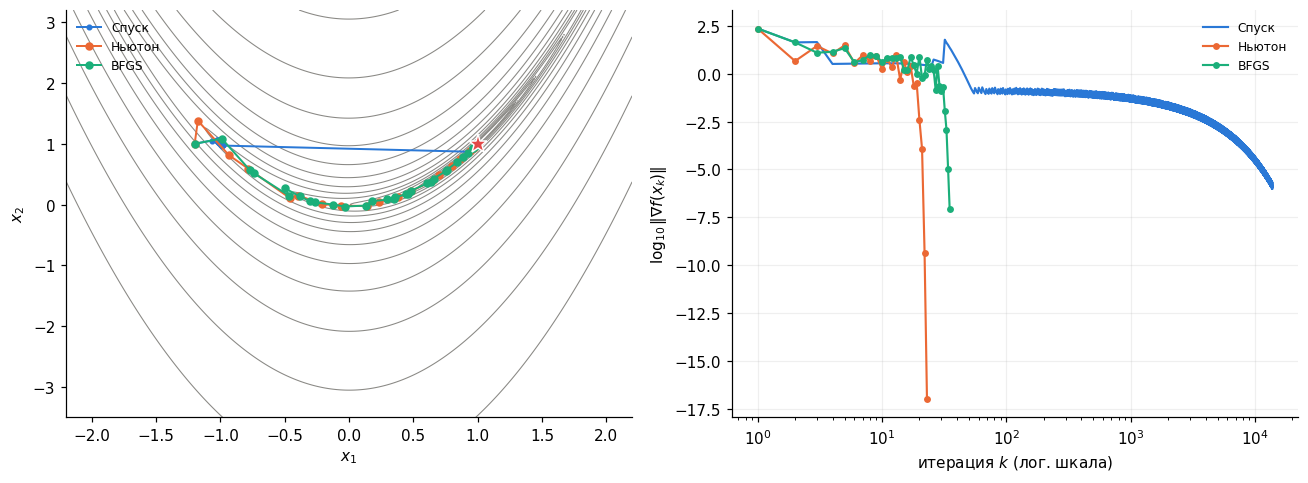

In [12]:
class FunctionCounter:
    def __init__(self, function):
        self.function = function
        self.calls = 0
    def __call__(self, x):
        self.calls += 1
        return self.function(x)

runs_rosen = {}
for name, solver in (
    ("Спуск", lambda f: gd(f, rosen_grad, X0_ROSEN)),
    ("Ньютон", lambda f: newton_damped(f, rosen_grad, rosen_hess, X0_ROSEN)),
    ("BFGS", lambda f: bfgs(f, rosen_grad, X0_ROSEN)),
):
    counted = FunctionCounter(rosen)
    result = solver(counted)
    runs_rosen[name] = (result, counted.calls)
    assert np.linalg.norm(rosen_grad(result[0])) <= (1e-10 if name == "Ньютон" else 1e-6)

print(f"{'Метод':<10} {'Итерации':>10} {'Вызовы f':>12} {'Точка':>29} {'||grad||':>12}")
for name, ((x, k, path, norms), calls) in runs_rosen.items():
    print(f"{name:<10} {k:>10} {calls:>12} {np.array2string(x, precision=7):>29} {norms[-1]:>12.2e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = list(runs_rosen)
paths = [runs_rosen[label][0][2] for label in labels]
norms = [runs_rosen[label][0][3] for label in labels]
plot_rosen_path(paths, labels, ax=axes[0])
plot_grad_norms(norms, labels, ax=axes[1])
fig.tight_layout()
plt.show()

**Ответ.** На Розенброке получилось 13 756 итераций спуска, 22 шага Ньютона и 34 шага BFGS. При одинаковом старте число вызовов цели составляет соответственно 150 555, 51 и 87: backtracking может проверять несколько значений $f$ на одной итерации. На графике спуск медленно идёт вдоль узкой долины (линейная сходимость), демпфированный Ньютон вблизи минимума переходит к полным шагам и квадратичной локальной сходимости. Для BFGS при подходящем поиске шага характерна сверхлинейная локальная сходимость; на графике виден резкий спад нормы градиента, хотя конечная последовательность сама по себе не доказывает асимптотический порядок.

У цепи $N=40$ спуск с $1/L$ дошёл до порога за 10 575 шагов, а Ньютон решил квадратичную задачу за один. Энергии совпали до показанных знаков, расстояние между решениями $2.43\cdot10^{-6}$. Для $N=10$ BFGS выполнил критерий за 40 итераций; для $N=20$ остановился на лимите 10 000 с $\|\nabla E\|\approx1.70\cdot10^{-6}>10^{-6}$. Одно условие Армихо требует достаточного уменьшения цели, но не контролирует кривизну в конце шага. Поэтому $s^\top y$ может быть слишком малым, обновления обратного гессиана пропускаются или оказываются неудачными. Условия Вольфе добавляют проверку кривизны и обычно улучшают работу BFGS.

In [13]:
energy40, grad40, H40, b40, v040 = make_chain(40)
L40 = np.linalg.eigvalsh(H40).max()
vg, kg, _, _ = gd(energy40, grad40, v040, alpha=1.0/L40)
vn = v040 - np.linalg.solve(H40, grad40(v040))
print(f"Цепь N=40: спуск {kg} итераций, E={energy40(vg):.9f}, ||grad||={np.linalg.norm(grad40(vg)):.2e}")
print(f"             Ньютон 1 шаг, E={energy40(vn):.9f}, ||grad||={np.linalg.norm(grad40(vn)):.2e}")
print(f"             ||v_gd-v_newton||={np.linalg.norm(vg-vn):.3e}")
assert np.linalg.norm(grad40(vg)) <= 1e-6
assert np.linalg.norm(vg-vn) < 1e-3

chain_bfgs = {}
for N in (10, 20):
    E, grad_E, H, b, v0 = make_chain(N)
    x, it, _, norms = bfgs(E, grad_E, v0, maxit=10_000)
    chain_bfgs[N] = (it, norms[-1], E(x))
    print(f"Цепь N={N}: BFGS {it} итераций, ||grad||={norms[-1]:.3e}, E={E(x):.9f}")

Цепь N=40: спуск 10575 итераций, E=13.441735585, ||grad||=9.99e-07
             Ньютон 1 шаг, E=13.441735585, ||grad||=1.88e-13
             ||v_gd-v_newton||=2.431e-06
Цепь N=10: BFGS 40 итераций, ||grad||=4.323e-09, E=78.050838338
Цепь N=20: BFGS 10000 итераций, ||grad||=1.699e-06, E=44.734724667


### (в) Гаусс–Ньютон на синусе из ДЗ 2 (2 балла)

**TODO 4 — шаг Гаусса–Ньютона.** Допишите в `gauss_newton` строку с направлением: $p$ — решение линейного МНК $\min_p\lVert Jp+r\rVert^2$ (`np.linalg.lstsq`). Длина шага — ваш `armijo` на $f=\tfrac12\lVert r\rVert^2$ (демпфированный Гаусс–Ньютон). Проверка под ячейкой: на **линейных** невязках $r=Ax-b$ метод обязан сойтись за одну итерацию к `lstsq`.

Затем:

1. Запустите из $(1,\,3,\,0)$: ожидается $7$ итераций и $f^\ast=1.1393$, $x^\ast\approx(2.10,\,2.997,\,0.700)$. Сравните с вашим `bfgs` на `sine_f` из того же старта (итерации и вызовы функции) и со спуском ($731$ итерация в конспекте).
2. Запустите из всех 20 стартов `starts` ДЗ 2 (`maxit=200`). Сколько стартов пришли к глобальному $f^\ast=1.1393$ (с точностью $10^{-6}$)? Нарисуйте данные и все 20 подогнанных кривых одной картинкой. Объясните в двух предложениях, почему быстрый локальный метод не отменяет мультистарт из ДЗ 2.

Критерии: полный балл — проверка на линейных невязках проходит, числа пункта 1 воспроизведены, картинка и объяснение; половина — метод сходится, но без сравнения или без мультистарта.

In [14]:
def gauss_newton(resid, jac, x0, tol=1e-6, maxit=100):
    """Демпфированный Гаусс–Ньютон для f=1/2 ||r||²."""
    f = lambda x: 0.5 * np.sum(resid(x) ** 2)
    x = np.asarray(x0, float).copy(); path = [x.copy()]; gnorm = []
    for k in range(maxit):
        r, J = resid(x), jac(x); g = J.T @ r; gnorm.append(np.linalg.norm(g))
        if gnorm[-1] <= tol:
            return x, k, np.array(path), np.array(gnorm)
        p = np.linalg.lstsq(J, -r, rcond=None)[0]
        x = x + armijo(f, x, p, g) * p; path.append(x.copy())
    return x, maxit, np.array(path), np.array(gnorm)

In [15]:
# проверка TODO 4: линейные невязки r = A x - b — один шаг из любого старта даёт решение lstsq
A_lin = rng.standard_normal((30, 4)); b_lin = rng.standard_normal(30)
x_lin, k_lin, _, _ = gauss_newton(lambda x: A_lin @ x - b_lin, lambda x: A_lin, np.ones(4), tol=1e-10)
assert k_lin == 1 and np.allclose(x_lin, np.linalg.lstsq(A_lin, b_lin, rcond=None)[0]), "на линейных невязках Гаусс–Ньютон должен совпасть с lstsq за одну итерацию: проверьте знак (-r) и что p решает именно min ||J p + r||"
print("TODO 4: ok")

TODO 4: ok


Метод             Итерации    Вызовы f/r         f(x)     ||grad||
Гаусс–Ньютон             7            22    1.1392731     3.19e-07
BFGS                    12            41    1.1392731     1.31e-07
Спуск                  731          8685    1.1392731     8.48e-07
Параметры Гаусса–Ньютона: [2.10139253 2.99669062 0.70026397]
Из 20 стартов к f=1.1392731 пришли 12 (60%)
Конечные значения: [ 1.13927  1.13927  1.13927  1.13927  1.13927 61.49727 61.68817  1.13927
  1.13927  1.13927 60.14144  1.13927 61.49727 61.49727 64.25178  1.13927
 64.25178  1.13927 64.22236  1.13927]
Останов по критерию градиента: 19 из 20


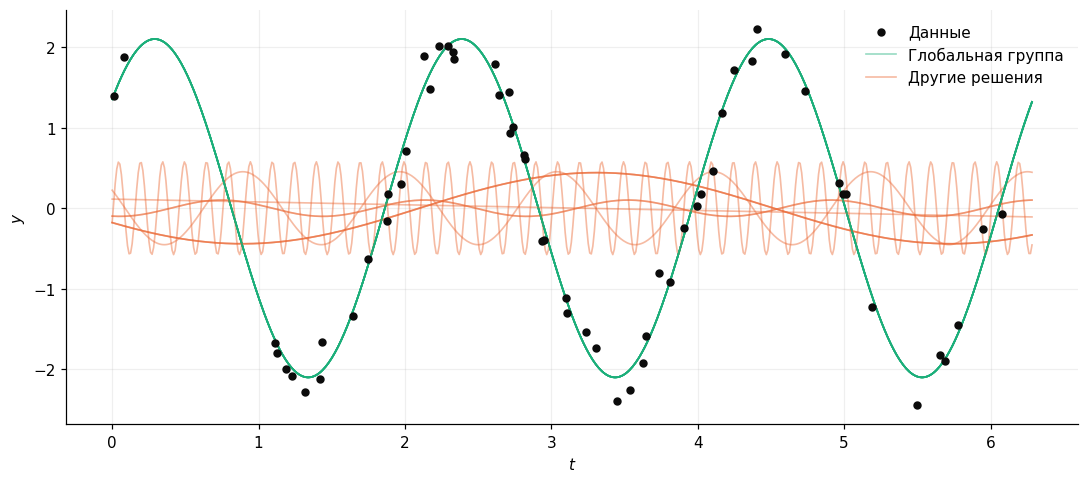

In [16]:
class ResidualCounter:
    def __init__(self, resid):
        self.resid, self.calls = resid, 0
    def __call__(self, x):
        self.calls += 1
        return self.resid(x)

counted_resid = ResidualCounter(sine_resid)
x_gn, it_gn, path_gn, norm_gn = gauss_newton(counted_resid, sine_jac, X0_SINE)
counted_bfgs = FunctionCounter(sine_f)
x_bfgs, it_bfgs, _, norm_bfgs = bfgs(counted_bfgs, sine_grad, X0_SINE)
counted_gd = FunctionCounter(sine_f)
x_gd, it_gd, _, norm_gd = gd(counted_gd, sine_grad, X0_SINE)
print(f"{'Метод':<15} {'Итерации':>10} {'Вызовы f/r':>13} {'f(x)':>12} {'||grad||':>12}")
for name, it, calls, x in (("Гаусс–Ньютон", it_gn, counted_resid.calls, x_gn),
                            ("BFGS", it_bfgs, counted_bfgs.calls, x_bfgs),
                            ("Спуск", it_gd, counted_gd.calls, x_gd)):
    print(f"{name:<15} {it:>10} {calls:>13} {sine_f(x):>12.7f} {np.linalg.norm(sine_grad(x)):>12.2e}")
print("Параметры Гаусса–Ньютона:", x_gn)
assert it_gn == 7 and abs(sine_f(x_gn) - 1.1392731) < 1e-6

gn_runs = [gauss_newton(sine_resid, sine_jac, start, maxit=200) for start in starts]
gn_values = np.array([sine_f(run[0]) for run in gn_runs])
best_value = sine_f(x_gn)
hits = np.isclose(gn_values, best_value, atol=1e-6, rtol=0)
print(f"Из 20 стартов к f={best_value:.7f} пришли {hits.sum()} ({hits.mean():.0%})")
print("Конечные значения:", np.array2string(gn_values, precision=5))
print("Останов по критерию градиента:", sum(run[1] < 200 for run in gn_runs), "из 20")

grid = np.linspace(0, 2*np.pi, 600)
plt.figure(figsize=(10, 4.5))
plt.scatter(t_data, y_data, color=INK, s=20, label="Данные", zorder=3)
for j, run in enumerate(gn_runs):
    params = run[0]
    curve = params[0]*np.sin(params[1]*grid + params[2])
    plt.plot(grid, curve, color=AQUA if hits[j] else ORANGE,
             alpha=0.45, lw=1.1, label=("Глобальная группа" if hits[j] else "Другие решения") if j in
             (next((i for i, h in enumerate(hits) if h), -1), next((i for i, h in enumerate(hits) if not h), -1)) else None)
plt.xlabel("$t$"); plt.ylabel("$y$"); plt.legend(); plt.tight_layout(); plt.show()

**Ответ.** Из $(1,3,0)$ Гаусс–Ньютон за 7 итераций получил $x\approx(2.1014,2.9967,0.7003)$ и $f\approx1.1392731$. BFGS потребовалось 12 итераций, спуску — 731; числа обращений к целевой функции у них 41 и 8685. Для Гаусса–Ньютона показаны 22 вызова функции невязок (включая вычисления градиента и проверки шага), поэтому этот счётчик не вполне совпадает по смыслу со счётчиками $f$ у двух других методов.

Из 20 стартов 12 дали значение в пределах $10^{-6}$ от $1.1392731$; 19 запусков выполнили критерий по норме градиента до лимита 200 итераций. Быстрый локальный метод всё равно чувствителен к стартовой частоте: другие запуски пришли к большим значениям. Мультистарт помогает найти лучшее из обнаруженных решений, но сам по себе не доказывает глобальную оптимальность.

## Бонус (+1 балл). L-BFGS своими руками

Реализуйте L-BFGS с памятью $m=5$: храните последние $m$ пар $(s_i,y_i)$ и вычисляйте $p=-H_kg$ двухпроходной рекурсией (*two-loop recursion*, Nocedal & Wright, алгоритм 7.4) с начальной матрицей $\gamma_kI$, $\gamma_k=s^\top y/y^\top y$ по последней паре; длина шага — ваш `armijo`. Запустите на цепи $N=40$ и сравните с `scipy.optimize.minimize(method="L-BFGS-B", options={"maxcor": 5})` по числу итераций (у SciPy — $75$) и с `np.linalg.solve` по времени; объясните, почему ваш вариант делает больше итераций (подсказка: §4.5 конспекта). Балл — за работающую рекурсию (проверка: на квадратичной $2\times2$ при $m\ge2$ после двух шагов направление совпадает с ньютоновским) и честное сравнение.

In [17]:
from time import perf_counter

def lbfgs_direction(g, pairs):
    """Два прохода с последними парами (s, y), начальная матрица gamma I."""
    q = g.copy()
    coeffs = []
    for s, y in reversed(pairs):
        rho = 1.0 / (y @ s)
        alpha = rho * (s @ q)
        q -= alpha * y
        coeffs.append((rho, alpha))
    if pairs:
        s, y = pairs[-1]
        gamma = (s @ y) / (y @ y)
    else:
        gamma = 1.0
    z = gamma * q
    for (s, y), (rho, alpha) in zip(pairs, reversed(coeffs)):
        beta = rho * (y @ z)
        z += s * (alpha - beta)
    return -z


def lbfgs(f, grad, x0, m=5, tol=1e-6, maxit=10_000):
    x = np.asarray(x0, float).copy()
    pairs = []
    g = grad(x)
    for k in range(maxit):
        if np.linalg.norm(g) <= tol:
            return x, k, np.linalg.norm(g)
        p = lbfgs_direction(g, pairs)
        s = armijo(f, x, p, g) * p
        x_new = x + s
        g_new = grad(x_new)
        y = g_new - g
        if s @ y > 1e-14:
            pairs.append((s.copy(), y.copy()))
            pairs = pairs[-m:]
        x, g = x_new, g_new
    return x, maxit, np.linalg.norm(g)

# Два точных шага на квадратичной задаче: проверяем действие обратного гессиана.
Q = np.diag([1.0, 50.0])
xq = np.array([50.0, 1.0]); secants = []
for _ in range(2):
    gq = Q @ xq
    pq = lbfgs_direction(gq, secants)
    alpha = -(gq @ pq) / (pq @ Q @ pq)
    s = alpha * pq
    secants.append((s, Q @ s))
    xq += s
check_g = np.array([2.0, -3.0])
check_p = lbfgs_direction(check_g, secants)
print("Квадратичная 2x2: направление L-BFGS", check_p,
      "; направление Ньютона", -np.linalg.solve(Q, check_g))
assert np.allclose(check_p, -np.linalg.solve(Q, check_g), atol=1e-9)

E40, grad40, H40, _, v040 = make_chain(40)
t0 = perf_counter()
x_lb, k_lb, norm_lb = lbfgs(E40, grad40, v040, m=5)
time_lb = perf_counter() - t0

t0 = perf_counter()
scipy_lb = minimize(E40, v040, jac=grad40, method="L-BFGS-B",
                    options={"maxcor": 5, "gtol": 1e-6})
time_scipy = perf_counter() - t0

t0 = perf_counter()
x_exact = v040 - np.linalg.solve(H40, grad40(v040))
time_solve = perf_counter() - t0
print(f"Свой L-BFGS: {k_lb} итераций, ||grad||={norm_lb:.2e}, "
      f"E={E40(x_lb):.9f}, время={time_lb:.4f} c")
print(f"SciPy L-BFGS-B: {scipy_lb.nit} итераций, ||grad||={np.linalg.norm(grad40(scipy_lb.x)):.2e}, "
      f"E={E40(scipy_lb.x):.9f}, время={time_scipy:.4f} c")
print(f"Прямое решение: E={E40(x_exact):.9f}, время={time_solve:.4f} c")
assert np.linalg.norm(x_lb - x_exact) < 1e-3

Квадратичная 2x2: направление L-BFGS [-2.    0.06] ; направление Ньютона [-2.    0.06]
Свой L-BFGS: 155 итераций, ||grad||=9.99e-07, E=13.441735585, время=0.0238 c
SciPy L-BFGS-B: 75 итераций, ||grad||=8.22e-04, E=13.441735607, время=0.0123 c
Прямое решение: E=13.441735585, время=0.0003 c


**Ответ.** Двухпроходная рекурсия с $m=5$ хранит лишь пять последних пар $(s,y)$, не формируя плотную матрицу $H_k$. На квадратичной задаче $2\times2$ после двух точных шагов она даёт то же направление для проверочного градиента, что и $-Q^{-1}g$.

Сравнение по времени здесь относится к одному запуску в этой среде и не является надёжным бенчмарком: на маленькой задаче накладные расходы Python существенны. Прямое решение использует постоянный гессиан квадратичной цепи и даёт точку минимума за один линейный solve. Разница числа итераций связана с поиском шага и критерием остановки: наша реализация использует лишь Армихо и требует нормы полного градиента $\le10^{-6}$, тогда как SciPy в данном запуске останавливается по относительному уменьшению функции при ещё заметной норме градиента. Поэтому сравнение числа итераций при настройках по умолчанию не следует понимать как сравнение при одинаковой точности. Условия Вольфе также контролируют кривизну пары $(s,y)$ и помогают сохранять полезные обновления.